In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [110]:
df=pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [153]:
df1=df.copy()
df1[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]] = df1[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]].replace(0,np.nan)
df1.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

<Axes: xlabel='Outcome', ylabel='count'>

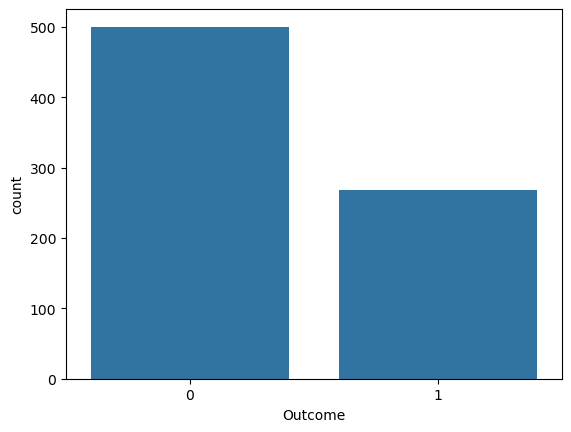

In [154]:
sns.countplot(data=df1,x="Outcome")

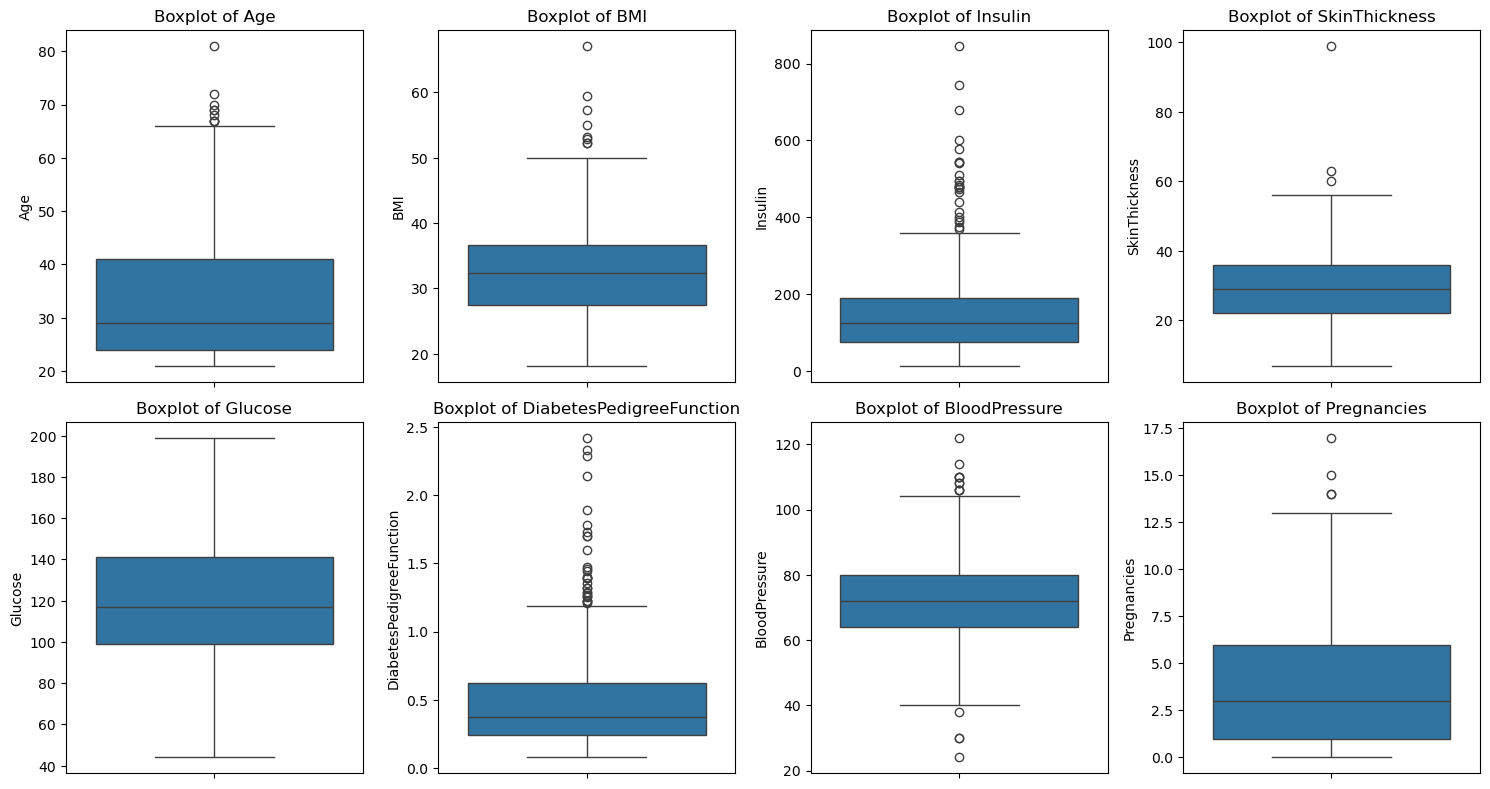

In [113]:
columns = ['Age', 'BMI', 'Insulin', 'SkinThickness', 'Glucose','DiabetesPedigreeFunction','BloodPressure','Pregnancies']

plt.figure(figsize=(15, 8))

for i, col in enumerate(columns):
    plt.subplot(2, 4, i+1)
    sns.boxplot(y=df1[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [114]:
out=[]
def z_score_outlier(df):
    m=np.mean(df)
    std=np.std(df)
    for i in df:
        z=(i-m)/std
        if np.abs(z)>3:
            out.append(i)
    print("outliers:",  out)
z_score_outlier(df1["Pregnancies"])

outliers: [15, 17, 14, 14]


In [115]:
out=[]
def z_score_outlier(df):
    m=np.mean(df)
    std=np.std(df)
    for i in df:
        z=(i-m)/std
        if np.abs(z)>3:
            out.append(i)
    print("outliers:",  out)
z_score_outlier(df1["Age"])

outliers: [69, 72, 81, 70, 69]


In [116]:
out=[]
def z_score_outlier(df):
    m=np.mean(df)
    std=np.std(df)
    for i in df:
        z=(i-m)/std
        if np.abs(z)>3:
            out.append(i)
    print("outliers:",  out)
z_score_outlier(df1["BMI"])

outliers: [55.0, 67.1, 59.4, 57.3]


In [117]:
out=[]
def z_score_outlier(df):
    m=np.mean(df)
    std=np.std(df)
    for i in df:
        z=(i-m)/std
        if np.abs(z)>3:
            out.append(i)
    print("outliers:",  out)
z_score_outlier(df1["Insulin"])

outliers: [543.0, 846.0, 744.0, 680.0, 545.0, 579.0, 600.0, 540.0]


In [118]:
out=[]
def z_score_outlier(df):
    m=np.mean(df)
    std=np.std(df)
    for i in df:
        z=(i-m)/std
        if np.abs(z)>3:
            out.append(i)
    print("outliers:",  out)
z_score_outlier(df1["SkinThickness"])

outliers: [63.0, 99.0]


In [119]:
out=[]
def z_score_outlier(df):
    m=np.mean(df)
    std=np.std(df)
    for i in df:
        z=(i-m)/std
        if np.abs(z)>3:
            out.append(i)
    print("outliers:",  out)
z_score_outlier(df1["DiabetesPedigreeFunction"])

outliers: [2.288, 1.893, 1.781, 2.329, 1.476, 2.137, 1.731, 1.6, 2.42, 1.699, 1.698]


In [123]:
out=[]
def Zscore_outlier(df):
    m = np.mean(df)
    sd = np.std(df)
    for i in df: 
        z = (i-m)/sd
        if np.abs(z) > 3: 
            out.append(i)
    print("Outliers:",out)
Zscore_outlier(df1["BloodPressure"])

Outliers: [30.0, 110.0, 122.0, 30.0, 110.0, 110.0, 24.0, 114.0]


<Axes: >

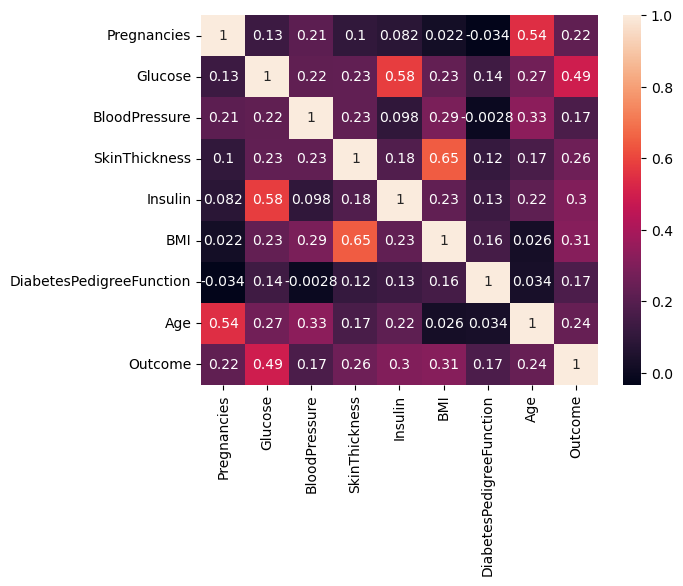

In [124]:
sns.heatmap(df1.corr(),annot=True)

In [128]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

X=df1.drop("Outcome",axis=1)
Y=df1["Outcome"]

x_train,x_test,y_train,y_test=train_test_split(X,Y, random_state=42,test_size=0.2,stratify=Y)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(614, 8)
(154, 8)
(614,)
(154,)


In [129]:
imputer = SimpleImputer(strategy="median")

x_train = pd.DataFrame(
    imputer.fit_transform(x_train),
    columns=X.columns,
    index=x_train.index
)

x_test = pd.DataFrame(
    imputer.transform(x_test),
    columns=X.columns,
    index=x_test.index
)

# 6. Remove outliers using Z-score from training data
z = np.abs((x_train - x_train.mean()) / x_train.std())

keep = (z < 3).all(axis=1)

x_train = x_train[keep]
y_train = y_train.loc[keep]

print("After removing outliers:")
print(x_train.shape)
print(y_train.shape)

After removing outliers:
(574, 8)
(574,)


In [130]:
from imblearn.over_sampling import RandomOverSampler

# Check class count before resampling
print("Before Resampling:")
print(y_train.value_counts())

# Apply Random Over Sampling
ros = RandomOverSampler(random_state=0)

x_train, y_train = ros.fit_resample(x_train, y_train)

# Check class count after resampling
print("\nAfter Resampling:")
print(y_train.value_counts())

# Check shapes
print("\nAfter Resampling Shapes:")
print(x_train.shape)
print(y_train.shape)

Before Resampling:
Outcome
0    381
1    193
Name: count, dtype: int64

After Resampling:
Outcome
0    381
1    381
Name: count, dtype: int64

After Resampling Shapes:
(762, 8)
(762,)


In [136]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
modelDTC=DecisionTreeClassifier(
                max_depth=5,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42
            )
modelDTC.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,5
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


Accuracy: 0.7662337662337663
Precision: 0.625
Recall: 0.8333333333333334
F1 Score: 0.7142857142857143


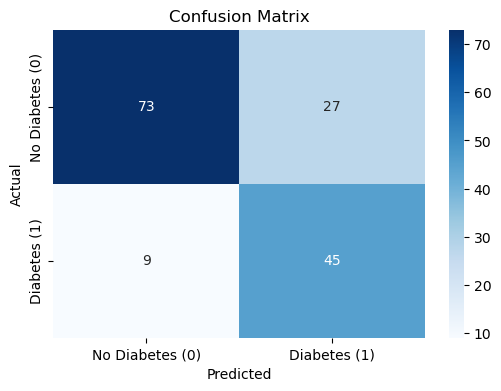

In [137]:
y_pred=modelDTC.predict(x_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

# plot Confusion Matrix 

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,  # Show the numbers inside each box
    fmt='d',  # Format numbers as integers (avoids scientific notation like 1.2e+02)
    cmap='Blues',  # Color theme ('Blues', 'Greens', 'Reds', 'coolwarm')
    xticklabels=['No Diabetes (0)', 'Diabetes (1)'],
    yticklabels=['No Diabetes (0)', 'Diabetes (1)'],
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

Accuracy: 0.7402597402597403
Precision: 0.6166666666666667
Recall: 0.6851851851851852
F1 Score: 0.6491228070175439


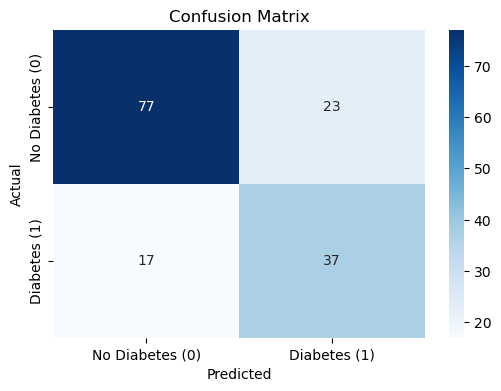

In [138]:
from sklearn.ensemble import RandomForestClassifier
modlRM=RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42
            )
modlRM.fit(x_train,y_train)


y_preds=modlRM.predict(x_test)
print("Accuracy:", accuracy_score(y_test, y_preds))
print("Precision:", precision_score(y_test, y_preds, zero_division=0))
print("Recall:", recall_score(y_test, y_preds, zero_division=0))
print("F1 Score:", f1_score(y_test, y_preds, zero_division=0))

cm = confusion_matrix(y_test, y_preds)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',  
    cmap='Blues',  
    xticklabels=['No Diabetes (0)', 'Diabetes (1)'],
    yticklabels=['No Diabetes (0)', 'Diabetes (1)'],
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


Accuracy: 0.7402597402597403
Precision: 0.609375
Recall: 0.7222222222222222
F1 Score: 0.6610169491525424


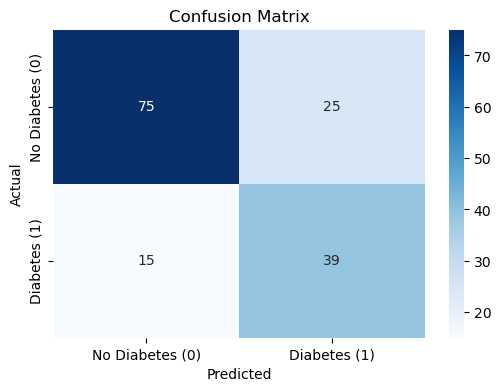

In [139]:
import xgboost as xgb
from xgboost import XGBClassifier
modelXGB=XGBClassifier(
                n_estimators=100,
                max_depth=3,
                learning_rate=0.1,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                eval_metric="logloss"
            )
modelXGB.fit(x_train,y_train)


y_prediction=modelXGB.predict(x_test)
print("Accuracy:", accuracy_score(y_test, y_prediction))
print("Precision:", precision_score(y_test, y_prediction, zero_division=0))
print("Recall:", recall_score(y_test, y_prediction, zero_division=0))
print("F1 Score:", f1_score(y_test, y_prediction, zero_division=0))

cm = confusion_matrix(y_test, y_prediction)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,  # Show the numbers inside each box
    fmt='d',  # Format numbers as integers (avoids scientific notation like 1.2e+02)
    cmap='Blues',  # Color theme ('Blues', 'Greens', 'Reds', 'coolwarm')
    xticklabels=['No Diabetes (0)', 'Diabetes (1)'],
    yticklabels=['No Diabetes (0)', 'Diabetes (1)'],
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [144]:
from sklearn.model_selection import train_test_split

df2 = df1.copy()

X1 = df2.drop("Outcome", axis=1)
Y1 = df2["Outcome"]

x_train1, x_test1, y_train1, y_test1 = train_test_split(
    X1, Y1, random_state=0, test_size=0.1, stratify=Y1
)

print(x_train1.shape)
print(x_test1.shape)
print(y_train1.shape)
print(y_test1.shape)

(691, 8)
(77, 8)
(691,)
(77,)


In [145]:
from sklearn.impute import SimpleImputer

imputer1 = SimpleImputer(strategy="median")

x_train1 = pd.DataFrame(
    imputer1.fit_transform(x_train1),
    columns=X1.columns,
    index=x_train1.index
)

x_test1 = pd.DataFrame(
    imputer1.transform(x_test1),
    columns=X1.columns,
    index=x_test1.index
)

z1 = np.abs((x_train1 - x_train1.mean()) / x_train1.std())

keep1 = (z1 < 3).all(axis=1)

x_train1 = x_train1[keep1]
y_train1 = y_train1.loc[keep1]

print(x_train1.shape)
print(y_train1.shape)

(647, 8)
(647,)


In [146]:
from imblearn.over_sampling import RandomOverSampler

ros1 = RandomOverSampler(random_state=0)

x_train1, y_train1 = ros1.fit_resample(x_train1, y_train1)

print(y_train1.value_counts())
print(x_train1.shape)
print(y_train1.shape)

Outcome
0    430
1    430
Name: count, dtype: int64
(860, 8)
(860,)


In [155]:
results = []

experiments = [
    ("Random State 42, Test Size 0.2", x_train, x_test, y_train, y_test, 42),
    ("Random State 0, Test Size 0.1", x_train1, x_test1, y_train1, y_test1, 0)
]

for exp_name, X_train, X_test, Y_train, Y_test, rs in experiments:

    models = {
        "Decision Tree": DecisionTreeClassifier(
            max_depth=5,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=rs
        ),

        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=rs
        ),

        "XGBoost": XGBClassifier(
            n_estimators=100,
            max_depth=3,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=rs,
            eval_metric="logloss"
        )
    }

    for model_name, model in models.items():

        model.fit(X_train, Y_train)
        y_pred = model.predict(X_test)

        results.append({
            "Experiment": exp_name,
            "Model": model_name,
            "Accuracy": round(accuracy_score(Y_test, y_pred) * 100, 2),
            "Precision": round(precision_score(Y_test, y_pred, zero_division=0) * 100, 2),
            "Recall": round(recall_score(Y_test, y_pred, zero_division=0) * 100, 2),
            "F1 Score": round(f1_score(Y_test, y_pred, zero_division=0) * 100, 2)
        })

comparison = pd.DataFrame(results)

display(comparison.sort_values("F1 Score", ascending=False))

,Experiment,Model,Accuracy,Precision,Recall,F1 Score
4,"Random State 0, Test Size 0.1",Random Forest,83.12,76.92,74.07,75.47
5,"Random State 0, Test Size 0.1",XGBoost,83.12,79.17,70.37,74.51
3,"Random State 0, Test Size 0.1",Decision Tree,77.92,63.89,85.19,73.02
0,"Random State 42, Test Size 0.2",Decision Tree,76.62,62.50,83.33,71.43
2,"Random State 42, Test Size 0.2",XGBoost,74.03,60.94,72.22,66.10
1,"Random State 42, Test Size 0.2",Random Forest,74.03,61.67,68.52,64.91


In [158]:
x=XGBClassifier(
            n_estimators=100,
            max_depth=3,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=0,
            eval_metric="logloss"
        )
x.fit(x_train1,y_train1)
y_predict=x.predict(x_test1)

In [160]:
y_prob=x.predict_proba(x_test1)[:,1]
result=[]
for threshold in [0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90]:
    y_predict=(y_prob>=threshold).astype(int)
    result.append({
        "Threshold": threshold,
        "Accuracy ": accuracy_score(y_test1,y_predict),
        "Precision": precision_score(y_test1, y_predict ,zero_division=0),
        "Recall": recall_score(y_test1, y_predict, zero_division=0),
        "F1 Score": f1_score(y_test1, y_predict, zero_division=0)
    })

    threshold_df = pd.DataFrame(result)
threshold_df

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.30,0.792208,0.648649,0.888889,0.750000
1,0.35,0.818182,0.696970,0.851852,0.766667
2,0.40,0.831169,0.733333,0.814815,0.771930
3,0.45,0.831169,0.769231,0.740741,0.754717
4,0.50,0.831169,0.791667,0.703704,0.745098
5,0.55,0.844156,0.826087,0.703704,0.760000
6,0.60,0.831169,0.818182,0.666667,0.734694
7,0.65,0.805195,0.833333,0.555556,0.666667
8,0.70,0.805195,0.875000,0.518519,0.651163
9,0.75,0.805195,0.928571,0.481481,0.634146


In [161]:

import joblib

joblib.dump({
    "model": x,
    "imputer": imputer1,
    "threshold": 0.40,
    "features": X1.columns.tolist(),
    "zero_columns": [
        "Glucose",
        "BloodPressure",
        "SkinThickness",
        "Insulin",
        "BMI"
    ]
}, "diabetes_model.pkl")

print("XGBoost model saved successfully!")


XGBoost model saved successfully!
